In [27]:
import numpy as np
import pandas as pd

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown

sys.path.append(str(Path.cwd().parent))
from src.models.predict import load_finalist_model, load_test_data,load_predicted_value
from src.models.evaluate import find_multiclass_best_threshold, evaluate_at_threshold_multiclass
from src.visualization.visualize import plot_confusion_matrix,plot_eval_comparison_chart

sys.path.append('..')

%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings('ignore',category=UserWarning)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# 1. Load Finalist Trained Models

In [28]:
loaded_models = load_finalist_model(modeling_mode='multi')
loaded_models

✅ Success: Model found at D:\All Practice Projects\Git Hub Projects\Machine-Failure-Prediction\models\multi
Loaded: LightGBM_pipeline.pkl
Loaded: XGBoost_pipeline.pkl
Total models loaded: 2
✅ 2 model(s) successfully loaded.


{'LightGBM_pipeline': Pipeline(steps=[('preprocess',
                  ColumnTransformer(transformers=[('num', StandardScaler(),
                                                   ['Air temperature [K]',
                                                    'Process temperature [K]',
                                                    'Rotational speed [rpm]',
                                                    'Torque [Nm]',
                                                    'Tool wear [min]']),
                                                  ('cat',
                                                   OneHotEncoder(handle_unknown='ignore',
                                                                 sparse_output=False),
                                                   ['Type'])])),
                 ('classifier',
                  LGBMClassifier(colsample_bytree=0.8, max_depth=7, num_class=6,
                                 objective='multiclass', random_state=42,
            

In [29]:
mdl_peipeline_xgb = loaded_models['XGBoost_pipeline']
mdl_peipeline_lgb = loaded_models['LightGBM_pipeline']

# 2. Load Test Data

In [30]:
test_data = load_test_data(modeling_mode='multi')
list(test_data.keys())

test data successfully loaded.


['X_test', 'X_train', 'y_test', 'y_train']

# 3. Load Predicted Data

In [31]:
pred_data = load_predicted_value(modeling_mode='multi')
list(pred_data.keys())

✅ Success: Predicted data found at D:\All Practice Projects\Git Hub Projects\Machine-Failure-Prediction\data\predict\multi
Loaded: LightGBM_predicted_prob.csv
Loaded: XGBoost_predicted_prob.csv
Total predicted data files loaded: 2
✅ 2 predicted data files successfully loaded.


['LightGBM_predicted_prob', 'XGBoost_predicted_prob']

In [32]:
y_prob_xgb = pd.DataFrame(pred_data['XGBoost_predicted_prob'])
y_prob_lgb = pd.DataFrame(pred_data['LightGBM_predicted_prob'])

# 4. Evaluation By Business Requirement

Let's assume business team want us to identify whether machine is going to fail at least **70%** of the time since it starts to operate, I planned to use recall as the primary evaluation metric. To achieve this, the probability threshold was adjusted to ensure recall ≥ 0.70, and precision was used as a secondary metric to reduce false positives.

In [34]:
# Finding threshold that achieves Recall >= 0.70
recall_target = 0.70

## 4.1 Evaluate By XGBClassifier

In [35]:
mdl_peipeline_xgb

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](6,)","[0,1,2,3,4,5]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Type','Air temperature [K]','Process temperature [K]', 'Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop

In [36]:
# get best threshold

best_threshold_result_xgb = find_multiclass_best_threshold(pipeline= mdl_peipeline_xgb,
                               y_proba_multiclass=y_prob_xgb,
                               y_true_multiclass= test_data['y_test'],
                               recall_target=  recall_target)

list(best_threshold_result_xgb.keys())

Best threshold for Recall >= 0.7: 0.519
Best Recall at this threshold: 0.700
Best Precision at this threshold: 0.907


['best_threshold',
 'best_precision',
 'best_recall',
 'y_true_binary',
 'y_proba_binary']

In [37]:
best_threshold_result_xgb['y_true_binary']

,MultiClass
0,1
1,0
2,0
3,0
4,0
...,...
1995,0
1996,0
1997,0
1998,0


In [38]:
best_threshold_result_xgb['y_proba_binary']

,0
0,0.871962
1,0.000643
2,0.000229
3,0.000081
4,0.000861
...,...
1995,0.000416
1996,0.000177
1997,0.000444
1998,0.000219


In [39]:
# get threshold result

eval_result_xgb = evaluate_at_threshold_multiclass(y_proba_binary= best_threshold_result_xgb['y_proba_binary'], 
                                                y_true_binary = best_threshold_result_xgb['y_true_binary'], 
                                                best_threshold = best_threshold_result_xgb['best_threshold'] )
                                

Confusion Matrix:
[[1925    5    0    0    0    0]
 [  21   49    0    0    0    0]
 [   0    0    0    0    0    0]
 [   0    0    0    0    0    0]
 [   0    0    0    0    0    0]
 [   0    0    0    0    0    0]]
Classification Report:
              precision    recall  f1-score   support

           0      0.989     0.997     0.993      1930
           1      0.907     0.700     0.790        70

    accuracy                          0.987      2000
   macro avg      0.948     0.849     0.892      2000
weighted avg      0.986     0.987     0.986      2000



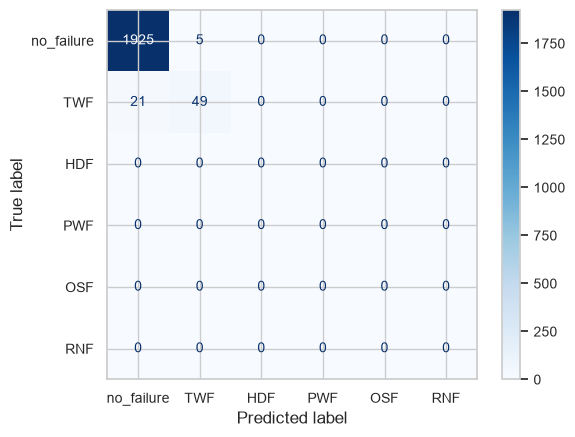

In [40]:
# plot confusion matrix

plot_confusion_matrix(confusion_matrix= eval_result_xgb['confusion_matrix_display'],
                     model_name=mdl_peipeline_xgb.named_steps['classifier'].__class__.__name__,
                     modeling_mode='multi')

## 4.2 Evaluate by Light GBM

In [41]:
mdl_peipeline_lgb

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](6,)","[0,1,2,3,4,5]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Type','Air temperature [K]','Process temperature [K]', 'Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop

In [42]:
# get best threshold

best_threshold_result_lgb = find_multiclass_best_threshold(pipeline= mdl_peipeline_lgb,
                               y_proba_multiclass=y_prob_lgb,
                               y_true_multiclass= test_data['y_test'],
                               recall_target=  recall_target)

list(best_threshold_result_lgb.keys())

Best threshold for Recall >= 0.7: 0.462
Best Recall at this threshold: 0.700
Best Precision at this threshold: 0.942


['best_threshold',
 'best_precision',
 'best_recall',
 'y_true_binary',
 'y_proba_binary']

In [43]:
best_threshold_result_lgb['y_true_binary']
best_threshold_result_lgb['y_proba_binary']


,0
0,0.472230
1,0.000006
2,0.000004
3,0.000009
4,0.000012
...,...
1995,0.000011
1996,0.000016
1997,0.000005
1998,0.000007


In [44]:
# get threshold result

eval_result_lgb = evaluate_at_threshold_multiclass(y_proba_binary= best_threshold_result_lgb['y_proba_binary'], 
                                                   y_true_binary = best_threshold_result_lgb['y_true_binary'], 
                                                   best_threshold = best_threshold_result_lgb['best_threshold'])
                                 

Confusion Matrix:
[[1927    3    0    0    0    0]
 [  21   49    0    0    0    0]
 [   0    0    0    0    0    0]
 [   0    0    0    0    0    0]
 [   0    0    0    0    0    0]
 [   0    0    0    0    0    0]]
Classification Report:
              precision    recall  f1-score   support

           0      0.989     0.998     0.994      1930
           1      0.942     0.700     0.803        70

    accuracy                          0.988      2000
   macro avg      0.966     0.849     0.899      2000
weighted avg      0.988     0.988     0.987      2000



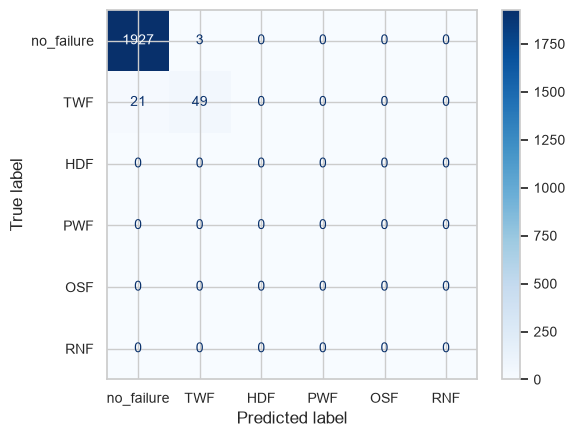

In [45]:
# plot confusion matrix

plot_confusion_matrix(confusion_matrix= eval_result_lgb['confusion_matrix_display'],
                     model_name=mdl_peipeline_lgb.named_steps['classifier'].__class__.__name__,
                     modeling_mode='multi')

# 5. Evaluation Summary
To compare the results from two different models for both metrics, I decided to create a line plot with a threshold level of 0.7, which aligns with the business requirements.

From the chart below, the Light GBM Classifier performs very well in both metrics compared with the other two classifiers, offering a stronger balance between recall and precision.

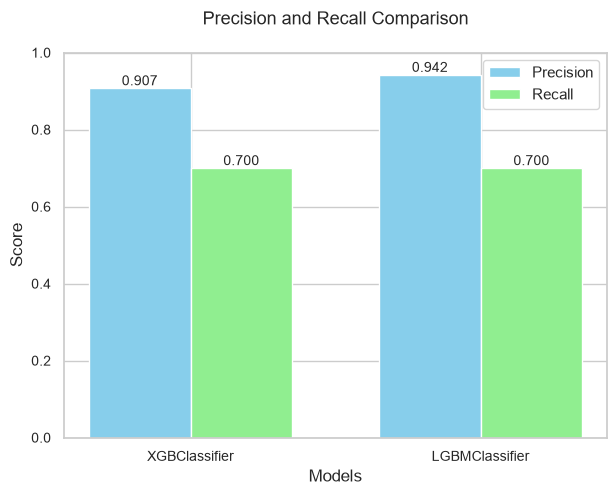

In [46]:
models = [mdl_peipeline_xgb.named_steps['classifier'].__class__.__name__, mdl_peipeline_lgb.named_steps['classifier'].__class__.__name__]
precision = [best_threshold_result_xgb['best_precision'], best_threshold_result_lgb['best_precision']]
recall = [best_threshold_result_xgb['best_recall'], best_threshold_result_lgb['best_recall']]

plot_eval_comparison_chart(model_list=models,
                           precision_list= precision,
                           recall_list= recall,
                           modeling_mode='multi')

# 6. Limitations and Future Work
Although manufacturing environments typically rely on batch scoring for machine failure prediction. I'd develop a FastAPI application to enable real-time scoring in next notebook. This approach allows incoming sensor data to be processed instantly, providing immediate failure risk predictions and supporting proactive maintenance decisions.

While batch scoring remains the standard approach in many manufacturing settings due to its simplicity and lower infrastructure requirements, real-time scoring demonstrates how predictive maintenance systems can be enhanced to deliver timely insights and support data-driven decision-making.

# 7. Deployment
We may deploy this model in a production environment using a batch scoring job to continuously monitor machine failure risks. The system can generate periodic predictions based on incoming operational data and track failure patterns across different factory shift types.

In addition, dashboards can be developed to visualize machine health, failure trends, and high-risk operating conditions for maintenance teams and plant managers.

Automated email alerts or notifications could also be triggered when the predicted failure probability exceeds a predefined threshold, enabling proactive maintenance and reducing unexpected downtime.